<a href="https://colab.research.google.com/github/samueladian3-cpu/ml-portfolio/blob/main/Pipeline_submission_BFGAI_Samuel_Adian.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Preparing Dependancies**

In [ ]:
# Install dependencies
!pip install -q diffusers==0.31.0 transformers==4.46.3 accelerate==1.1.1 huggingface_hub==0.26.2
!pip install -q safetensors matplotlib pillow

# ===== Semua import library disatukan di sini (di awal proyek) =====
import gc
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter

from diffusers import (
    StableDiffusionPipeline,
    StableDiffusionImg2ImgPipeline,
    StableDiffusionInpaintPipeline,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler,
    DDIMScheduler,
)
from transformers import pipeline as hf_pipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print("Device:", device, "| dtype:", dtype)

def flush():
    """Bersihkan RAM GPU."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def show_image(img, title=None, figsize=(5, 5)):
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()

Device: cuda | dtype: torch.float16


# **Kriteria 1: Melakukan Image Generation dari Teks (Text-to-Image)**

## **Load Base Pipeline Model**

In [ ]:
# Load Base Pipeline Stable Diffusion v1-5 (dipakai ulang untuk semua task text-to-image)
pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=dtype,
    safety_checker=None
).to(device)

# Simpan konfigurasi scheduler default agar bisa direset saat eksperimen scheduler
default_scheduler_config = pipe.scheduler.config

print("Base pipeline loaded:", pipe.__class__.__name__)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Base pipeline loaded: StableDiffusionPipeline


## **Generate Image**

  0%|          | 0/50 [00:00<?, ?it/s]

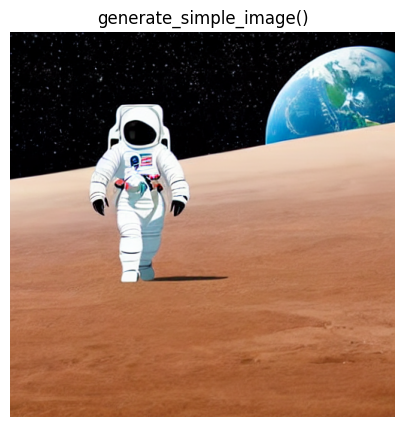

In [ ]:
# Prompt & negative prompt sesuai instruksi: gaya 2D digital illustration (kartun datar)
# Dipakai konsisten di kedua fungsi agar hasilnya bisa dibandingkan secara objektif
PROMPT = "an astronaut with full white spacesuit, standing on a flat moon plain, with earth in the background, minimal detail, 2D digital illustration"
NEGATIVE_PROMPT = "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"
SEED = 222

def generate_simple_image(prompt, negative_prompt, seed):
    """Fungsi standar text-to-image dengan parameter dasar (prompt, negative_prompt, seed)."""
    generator = torch.Generator(device=device).manual_seed(seed)
    image = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator
    ).images[0]
    return image

simple_image = generate_simple_image(PROMPT, NEGATIVE_PROMPT, SEED)
show_image(simple_image, "generate_simple_image()")

## **Generate Image with Hyperparameter Configuration**

  0%|          | 0/50 [00:00<?, ?it/s]

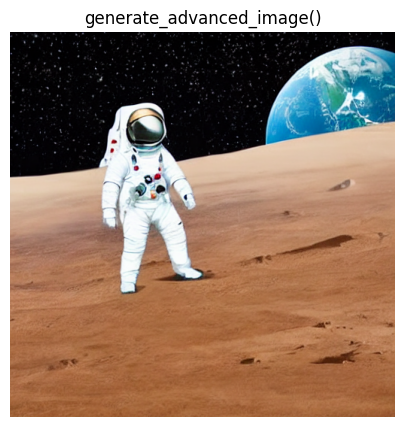

In [ ]:
def generate_advanced_image(prompt, negative_prompt, seed, guidance_scale, num_inference_steps):
    """Fungsi text-to-image dengan parameter tambahan: guidance_scale & num_inference_steps."""
    generator = torch.Generator(device=device).manual_seed(seed)
    image = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps
    ).images[0]
    return image

# Prompt sama persis dengan fungsi simple agar bisa dibandingkan secara objektif.
# Pembedanya: guidance_scale & num_inference_steps dipertegas agar detail objek lebih jelas.
advanced_image = generate_advanced_image(
    PROMPT, NEGATIVE_PROMPT, SEED,
    guidance_scale=5.0,
    num_inference_steps=50
)
show_image(advanced_image, "generate_advanced_image()")

## **Guidance Scale Comparison**

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

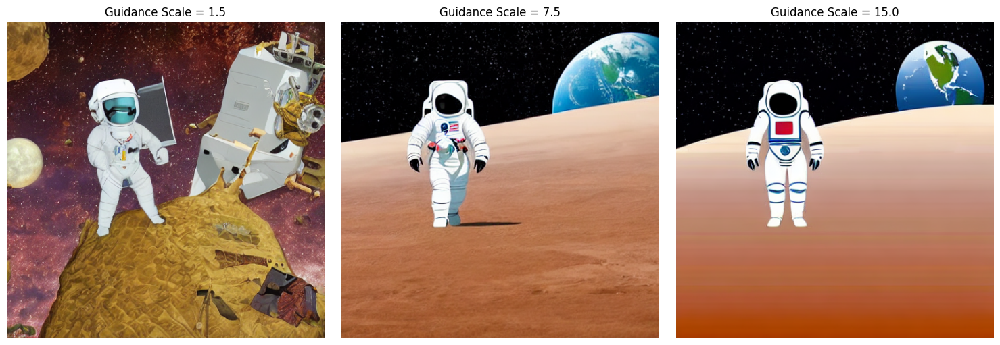

In [ ]:
# Eksperimen Guidance Scale: bandingkan nilai rendah vs tinggi (step dibuat tetap)
guidance_values = [1.5, 7.5, 15.0]
fig, axes = plt.subplots(1, len(guidance_values), figsize=(15, 5))

for ax, g in zip(axes, guidance_values):
    img = generate_advanced_image(
        PROMPT, NEGATIVE_PROMPT, SEED,
        guidance_scale=g,
        num_inference_steps=50
    )
    ax.imshow(img)
    ax.set_title(f"Guidance Scale = {g}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### **Guidance Scale Explanation:**

*   **Gambar dengan "Scale" Rendah:**
Pada guidance scale rendah (1.5), model hanya sedikit mengikuti prompt sehingga komposisi terlihat bebas dan kurang terkontrol. Objek astronaut dan latar bulan masih muncul, tetapi penempatan dan proporsinya kurang akurat serta beberapa bagian tampak melebur. Variasi visual tinggi namun kesesuaian dengan prompt rendah.

*   **Gambar dengan "Scale" Tinggi:**
Pada guidance scale tinggi (15.0), gambar menjadi sangat patuh terhadap prompt: astronaut, permukaan bulan, dan bumi tampil jelas dan tegas. Namun gaya ilustrasi cenderung menjadi lebih kaku dan kontras berlebih. Nilai menengah-rendah (sekitar 5-7.5) memberi keseimbangan terbaik antara kesesuaian prompt dan gaya 2D yang natural sesuai yang diharapkan.

## **Inference Steps Comparison**

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

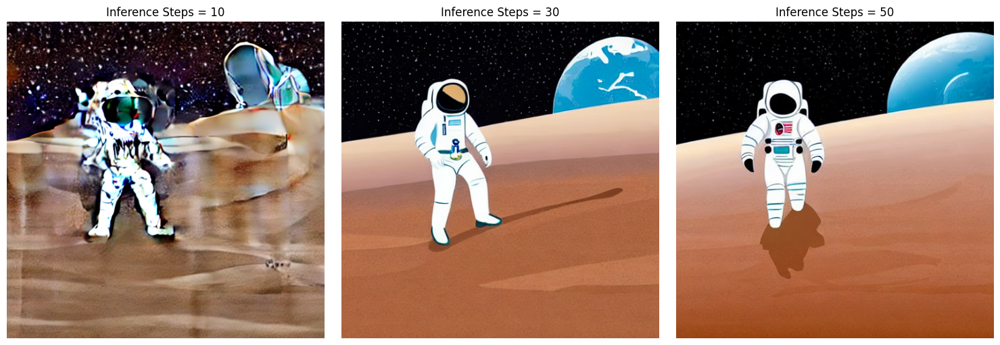

In [ ]:
# Eksperimen Inference Steps: step rendah (5-15) vs step tinggi (30-50), guidance dibuat tetap
step_values = [10, 30, 50]
fig, axes = plt.subplots(1, len(step_values), figsize=(15, 5))

for ax, s in zip(axes, step_values):
    img = generate_advanced_image(
        PROMPT, NEGATIVE_PROMPT, SEED,
        guidance_scale=9.0,
        num_inference_steps=s
    )
    ax.imshow(img)
    ax.set_title(f"Inference Steps = {s}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### **Inference Step Explanation:**

*   **Gambar dengan "Step" Rendah:**
Pada jumlah step rendah (10), proses denoising belum selesai sehingga hasil masih kasar dan kurang detail. Garis dan bidang warna ilustrasi belum tegas, serta masih terdapat noise terutama pada area latar.

*   **Gambar dengan "Step" Tinggi:**
Pada jumlah step tinggi (30 dan 50), gambar menjadi lebih halus, bersih, dan stabil. Bidang warna lebih solid dan tepi objek lebih rapi. Perbedaan antara step 30 dan 50 relatif kecil, menandakan hasil sudah mulai konvergen sehingga penambahan step lebih lanjut hanya memberi peningkatan kualitas yang minim.

## **Batch Inference from One Prompt**

  0%|          | 0/50 [00:00<?, ?it/s]

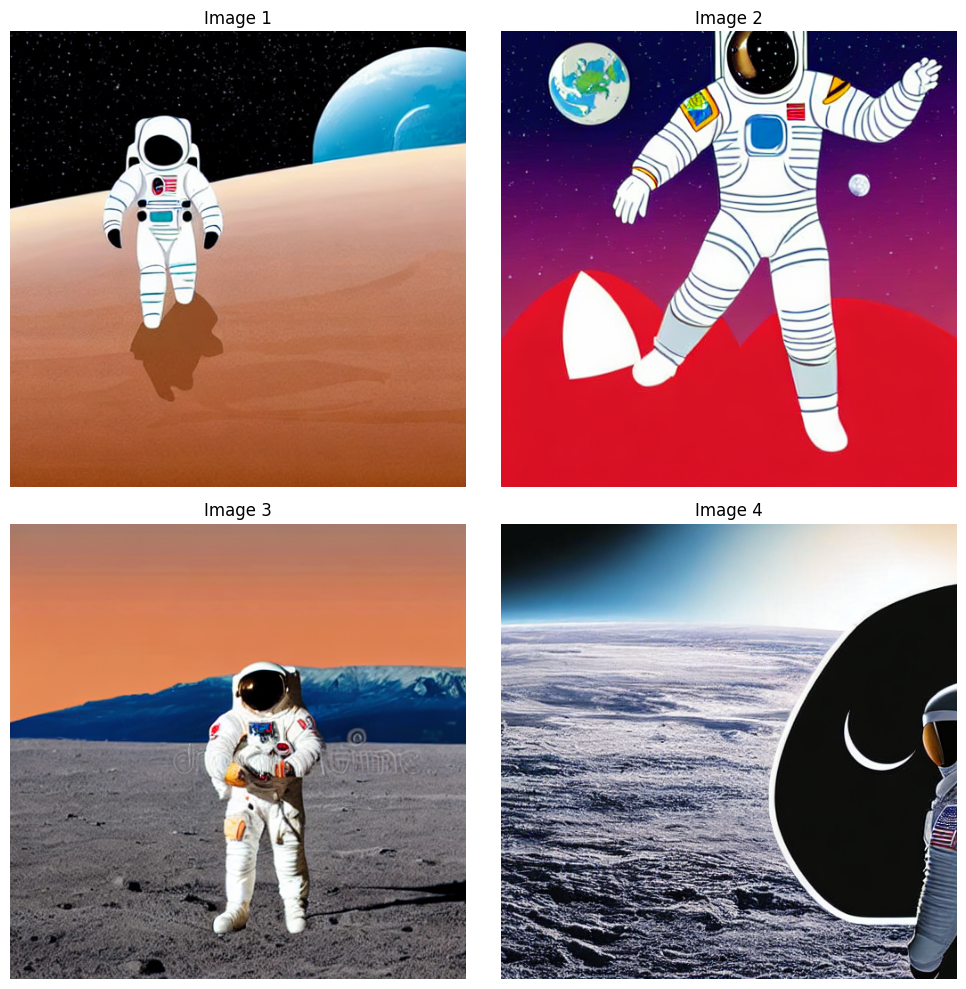

In [ ]:
# Batch Inference: hasilkan 4 gambar sekaligus dari 1 prompt, tampilkan grid 2x2
generator = torch.Generator(device=device).manual_seed(SEED)
batch_result = pipe(
    prompt=[PROMPT] * 4,
    negative_prompt=[NEGATIVE_PROMPT] * 4,
    generator=generator,
    guidance_scale=9.0,
    num_inference_steps=50
).images

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, img, idx in zip(axes.flatten(), batch_result, range(1, 5)):
    ax.imshow(img)
    ax.set_title(f"Image {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## **Load Scheduler**

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

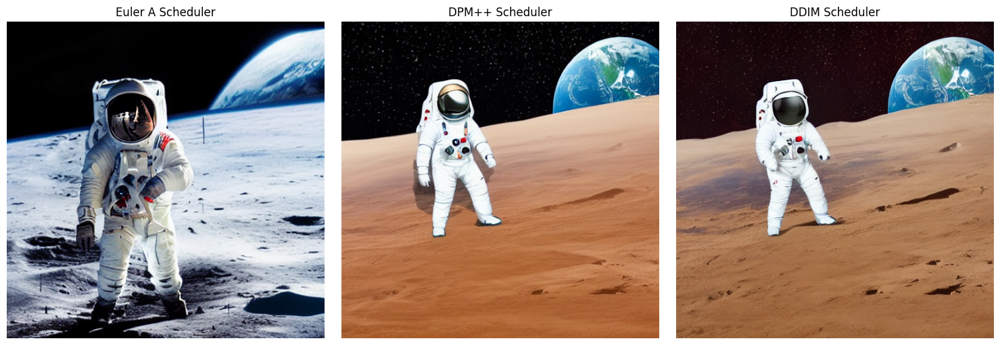

In [ ]:
def load_scheduler(pipe, scheduler_name):
    """Ganti algoritma sampling tanpa memuat ulang model."""
    if scheduler_name == "Euler A":
        pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
    elif scheduler_name == "DPM++":
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    elif scheduler_name == "DDIM":
        pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
    return pipe

# Bandingkan 3 scheduler dengan parameter identik
schedulers = ["Euler A", "DPM++", "DDIM"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, name in zip(axes, schedulers):
    pipe = load_scheduler(pipe, name)
    img = generate_advanced_image(
        PROMPT, NEGATIVE_PROMPT, SEED,
        guidance_scale=5.0,
        num_inference_steps=30
    )
    ax.imshow(img)
    ax.set_title(f"{name} Scheduler")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Kembalikan ke scheduler default
pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(default_scheduler_config)

### **Scheduler Comparation:**

*   **Gambar dengan "Euler A Scheduler":**
Euler Ancestral menghasilkan gambar yang ekspresif dengan variasi detail sedikit lebih banyak karena sifat ancestral-nya yang menambah noise acak di tiap step. Pada step menengah (30) hasilnya sudah cukup jelas dengan komposisi yang baik.

*   **Gambar dengan "DPM++ Scheduler":**
DPM++ (DPMSolverMultistep) konvergen lebih cepat dan efisien. Pada jumlah step yang sama, hasilnya cenderung paling bersih dan rapi, cocok untuk menghasilkan gambar berkualitas dengan step lebih sedikit.

*   **Gambar dengan "DDIM Scheduler":**
DDIM bersifat deterministik dan menghasilkan gambar yang halus serta konsisten. Karakteristiknya sedikit lebih lembut dibanding DPM++, dengan hasil stabil namun terkadang ketajamannya sedikit lebih rendah pada step yang rendah.

# **Kriteria 2: Menyempurnakan Gambar Melalui Image-to-Image**

## **Base + Refiner Image Generation**

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/40 [00:00<?, ?it/s]

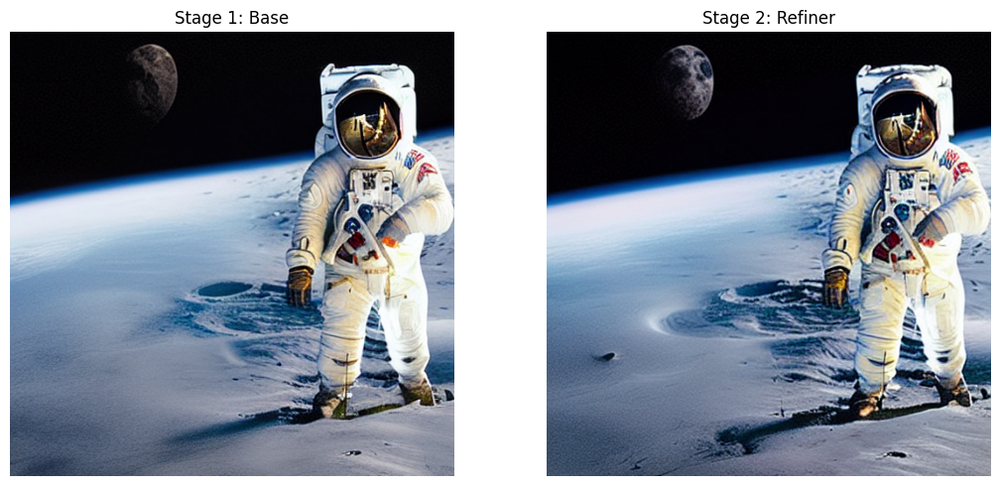

In [ ]:
# Refiner Pattern: Two-Stage Generation (Base + Refiner) memakai checkpoint yang sama.
# Stage 1 (Base) menghasilkan gambar awal, Stage 2 (Img2Img) menyempurnakannya.

# Reuse komponen pipe yang sama agar hemat VRAM (tanpa load model baru)
pipe_img2img = StableDiffusionImg2ImgPipeline(**pipe.components)
pipe_img2img.set_progress_bar_config(disable=True)

# Stage 1: Base menghasilkan gambar awal
generator = torch.Generator(device=device).manual_seed(SEED)
base_image = pipe(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    generator=generator,
    guidance_scale=5.0,
    num_inference_steps=40
).images[0]

# Stage 2: Refiner menyempurnakan hasil Stage 1 (strength kecil = hanya memperhalus)
generator = torch.Generator(device=device).manual_seed(SEED)
refined_image = pipe_img2img(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    image=base_image,
    generator=generator,
    guidance_scale=5.0,
    num_inference_steps=40,
    strength=0.3
).images[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(base_image); axes[0].set_title("Stage 1: Base"); axes[0].axis("off")
axes[1].imshow(refined_image); axes[1].set_title("Stage 2: Refiner"); axes[1].axis("off")
plt.tight_layout()
plt.show()

## **Inpainting**

### **Load Model Inpainting**

In [ ]:
# Model khusus inpainting sesuai instruksi
pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
    "runwayml/stable-diffusion-inpainting",
    torch_dtype=dtype,
    safety_checker=None
).to(device)

print("Inpainting pipeline loaded:", pipe_inpaint.__class__.__name__)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
You have disabled the safety checker for <class 'diffusers.pipelin

Inpainting pipeline loaded: StableDiffusionInpaintPipeline


### **Manual Masking**

/tmp/ipykernel_3678/3009456062.py:6: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  manual_mask = Image.fromarray(mask_array, mode="L")


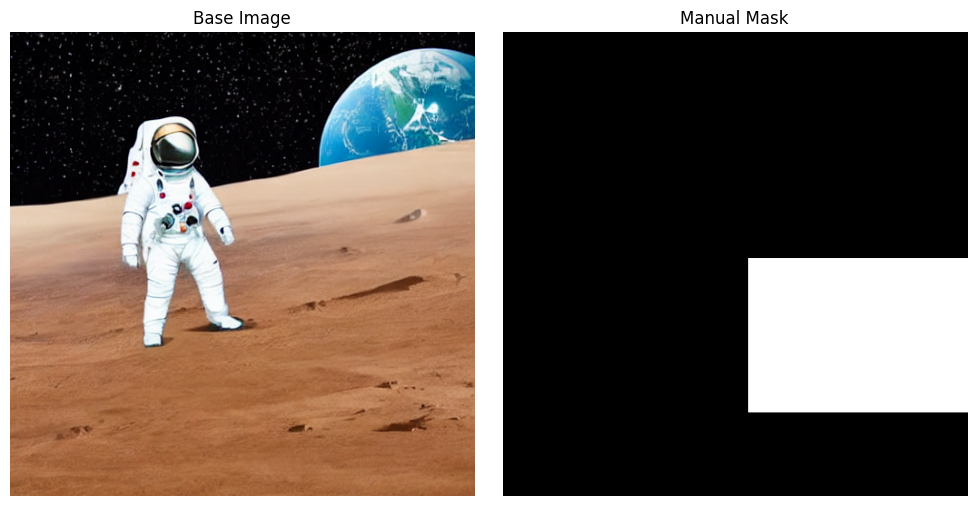

In [ ]:
# Manual masking: area mask di sisi kanan astronaut untuk broken satellite
base_for_inpaint = advanced_image.convert("RGB").resize((512, 512))

mask_array = np.zeros((512, 512), dtype=np.uint8)
mask_array[250:420, 270:512] = 255
manual_mask = Image.fromarray(mask_array, mode="L")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(base_for_inpaint); axes[0].set_title("Base Image"); axes[0].axis("off")
axes[1].imshow(manual_mask, cmap="gray"); axes[1].set_title("Manual Mask"); axes[1].axis("off")
plt.tight_layout()
plt.show()

### **Generate**

  0%|          | 0/80 [00:00<?, ?it/s]

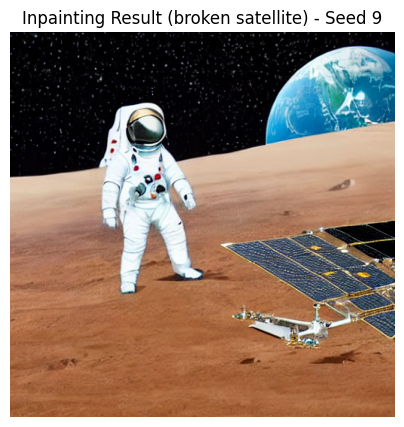

In [ ]:
INPAINT_SEED = 9

def inpaint_engine(image, mask, prompt, negative_prompt=None, seed=INPAINT_SEED,
                   guidance_scale=16.0, num_inference_steps=80, strength=1.0):
    """Inpainting: menerima input image, mask, dan prompt menggunakan model inpainting."""
    if image.mode != "RGB":
        image = image.convert("RGB")
    if mask.mode != "L":
        mask = mask.convert("L")
    if image.size != mask.size:
        mask = mask.resize(image.size, resample=Image.NEAREST)

    generator = torch.Generator(device=device).manual_seed(seed)
    result = pipe_inpaint(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=image,
        mask_image=mask,
        generator=generator,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps,
        strength=strength
    ).images[0]
    return result

# Prompt sesuai saran reviewer (guidance & step tinggi agar satelit terbentuk jelas)
prompt_satellite = (
    "a damaged broken satellite crashed on the moon surface, "
    "lunar surface with craters, metallic debris, broken panels, exposed mechanical parts, "
    "multi-legged landing gear, crashed on Mars surface, "
    "highly detailed mechanical structure, sharp focus, "
    "realistic scale, photorealistic, cinematic lighting"
)
negative_prompt_satellite = "blurry, low quality, distorted, messy, cartoon, drawing, painting"

inpaint_result = inpaint_engine(base_for_inpaint, manual_mask, prompt_satellite,
                                negative_prompt=negative_prompt_satellite)
show_image(inpaint_result, "Inpainting Result (broken satellite) - Seed 9")

## **Inpainting Menggunakan Automasking**

### **load Model Segmentation Untuk Masking**

In [ ]:
# Model segmentation untuk menghasilkan mask otomatis
segmenter = hf_pipeline(
    "image-segmentation",
    model="nvidia/segformer-b0-finetuned-ade-512-512",
    device=0 if device == "cuda" else -1
)

print("Segmentation model loaded.")

Segmentation model loaded.


### **Masking with Segmentation Model**

/tmp/ipykernel_3678/3102879747.py:8: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  auto_mask = Image.fromarray(auto_mask_array, mode="L")


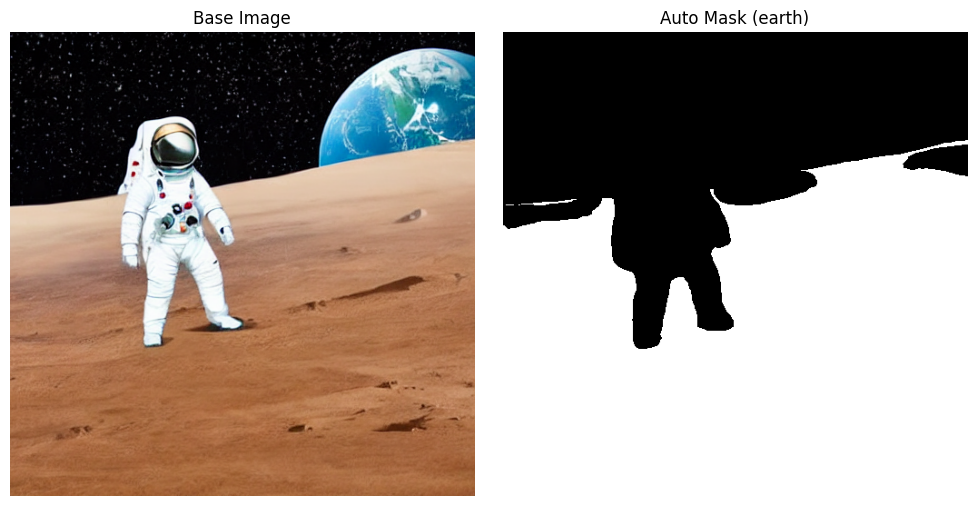

In [ ]:
# Auto-masking: gunakan model segmentation untuk membuat mask area objek otomatis.
# Pilih segmen dengan area terbesar sebagai area yang akan di-edit.
seg_results = segmenter(base_for_inpaint)
seg_results = sorted(seg_results, key=lambda s: np.array(s["mask"]).sum(), reverse=True)

target_mask = seg_results[0]["mask"].convert("L").resize((512, 512), resample=Image.NEAREST)
auto_mask_array = (np.array(target_mask) > 127).astype(np.uint8) * 255
auto_mask = Image.fromarray(auto_mask_array, mode="L")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(base_for_inpaint); axes[0].set_title("Base Image"); axes[0].axis("off")
axes[1].imshow(auto_mask, cmap="gray"); axes[1].set_title(f"Auto Mask ({seg_results[0]['label']})"); axes[1].axis("off")
plt.tight_layout()
plt.show()

### **Generate**

  0%|          | 0/80 [00:00<?, ?it/s]

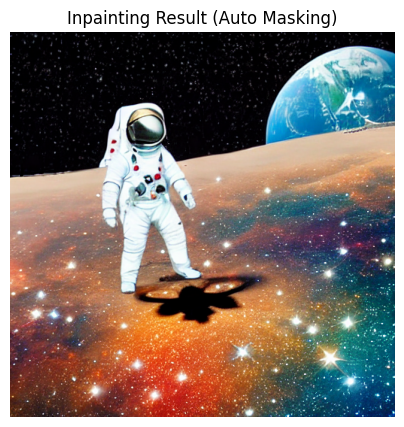

In [ ]:
# Generate inpainting menggunakan mask otomatis dari model segmentation
auto_inpaint_prompt = "a colorful nebula and bright stars in deep space, detailed, sharp focus"
auto_inpaint_neg = "blurry, low quality, deformed, text, watermark"
auto_inpaint_result = inpaint_engine(base_for_inpaint, auto_mask, auto_inpaint_prompt,
                                     negative_prompt=auto_inpaint_neg)
show_image(auto_inpaint_result, "Inpainting Result (Auto Masking)")

## **Outpainting**

### **Prepare the Canvas**

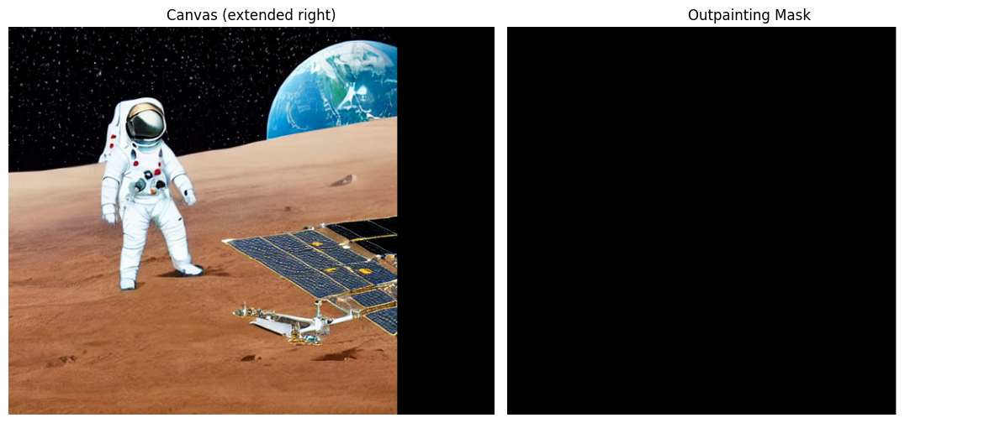

In [ ]:
def prepare_outpainting(image, direction="right", expand_pixels=128):
    """Perluas kanvas ke satu arah (kiri/kanan/atas/bawah) dan buat mask area baru."""
    if image.mode != "RGB":
        image = image.convert("RGB")
    # Samakan ke 512x512 agar konsisten dan kelipatan 8
    image = image.resize((512, 512))
    w, h = image.size

    if direction in ("left", "right"):
        new_w, new_h = w + expand_pixels, h
    else:
        new_w, new_h = w, h + expand_pixels
    new_w -= new_w % 8
    new_h -= new_h % 8

    canvas = Image.new("RGB", (new_w, new_h), (0, 0, 0))
    mask = Image.new("L", (new_w, new_h), 255)   # putih = area baru (edit)
    keep = Image.new("L", (w, h), 0)             # hitam = area asli (keep)

    if direction == "right":
        paste_xy = (0, 0)
    elif direction == "left":
        paste_xy = (new_w - w, 0)
    elif direction == "up":
        paste_xy = (0, new_h - h)
    else:
        paste_xy = (0, 0)

    canvas.paste(image, paste_xy)
    mask.paste(keep, paste_xy)
    return canvas, mask

# Gunakan hasil inpainting sebelumnya sebagai input outpainting
out_canvas, out_mask = prepare_outpainting(inpaint_result, direction="right", expand_pixels=128)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(out_canvas); axes[0].set_title("Canvas (extended right)"); axes[0].axis("off")
axes[1].imshow(out_mask, cmap="gray"); axes[1].set_title("Outpainting Mask"); axes[1].axis("off")
plt.tight_layout()
plt.show()

### **Generate**

  0%|          | 0/50 [00:00<?, ?it/s]

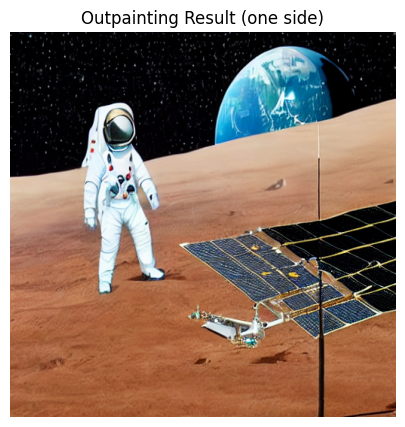

In [ ]:
# Outpainting satu sisi: isi area baru hanya dengan langit & permukaan bulan (tanpa struktur)
outpaint_prompt = "empty moon surface and dark starry sky, barren lunar ground, calm deep space, seamless natural continuation"
outpaint_neg = "building, structure, machine, satellite, robot, debris, text, watermark, busy, cluttered, blurry, low quality, deformed"
outpaint_result = inpaint_engine(out_canvas, out_mask, outpaint_prompt,
                                 negative_prompt=outpaint_neg, num_inference_steps=50, strength=1.0)
show_image(outpaint_result, "Outpainting Result (one side)", figsize=(7, 5))

## **Outpainting Zoom Out**

### **Prepare Canvas for Zoom Out**

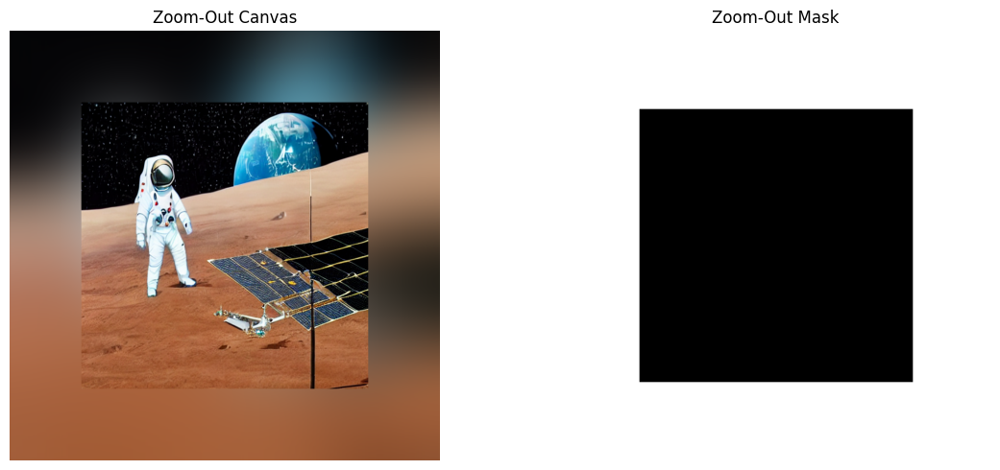

In [ ]:
def prepare_zoom_out(image, expand_pixels=128):
    """Zoom-out: perluas kanvas ke segala arah, gambar asli di tengah."""
    if image.mode != "RGB":
        image = image.convert("RGB")
    image = image.resize((512, 512))
    w, h = image.size

    new_w = w + expand_pixels * 2
    new_h = h + expand_pixels * 2
    new_w -= new_w % 8
    new_h -= new_h % 8

    # Latar blur halus agar transisi tidak tajam
    bg = image.resize((new_w, new_h), resample=Image.BICUBIC).filter(ImageFilter.GaussianBlur(60))
    canvas = bg.copy()

    paste_x = (new_w - w) // 2
    paste_y = (new_h - h) // 2
    canvas.paste(image, (paste_x, paste_y))

    # Mask area baru (putih), lalu kecilkan area 'keep' sedikit (feather) agar tepi menyatu
    mask = Image.new("L", (new_w, new_h), 255)
    feather = 12
    keep = Image.new("L", (w - feather * 2, h - feather * 2), 0)
    mask.paste(keep, (paste_x + feather, paste_y + feather))
    return canvas, mask

zoom_canvas, zoom_mask = prepare_zoom_out(outpaint_result, expand_pixels=128)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(zoom_canvas); axes[0].set_title("Zoom-Out Canvas"); axes[0].axis("off")
axes[1].imshow(zoom_mask, cmap="gray"); axes[1].set_title("Zoom-Out Mask"); axes[1].axis("off")
plt.tight_layout()
plt.show()

### **Generate**

  0%|          | 0/50 [00:00<?, ?it/s]

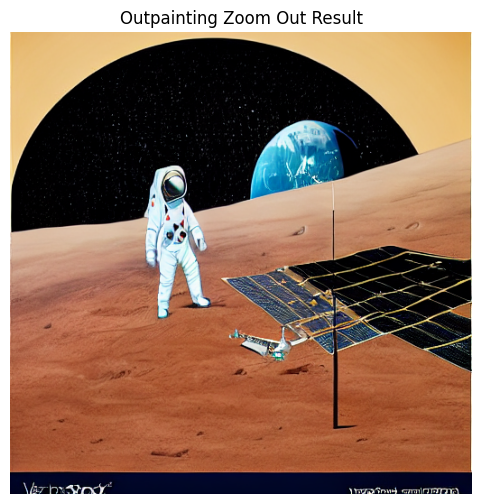

In [ ]:
# Generate Zoom Out: isi area sekeliling hanya dengan langit & tanah bulan yang bersih
zoom_prompt = "wide empty view of a vast barren moon surface under a dark starry sky, distant planet earth, minimal simple clean lunar landscape, calm deep space"
zoom_neg = "building, structure, machine, robot, debris, pole, line, text, watermark, busy, cluttered, complex, blurry, low quality, deformed"
zoom_result = inpaint_engine(zoom_canvas, zoom_mask, zoom_prompt,
                             negative_prompt=zoom_neg, num_inference_steps=50, strength=1.0)
show_image(zoom_result, "Outpainting Zoom Out Result", figsize=(7, 6))

flush()